# Tugas - Klasifikasi dengan Decision Tree

| Nama | NRP |
|------|-----|
| Rasya Gonawi | 5054251032|

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model Decision Tree Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja Decision Tree secara praktik, khususnya:
1. Perbedaan hasil antara kriteria split Gini Impurity dan Entropy
2. Pengaruh regularisasi (max_depth) terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Decision Tree dengan kriteria Gini dan Entropy.
   - Lakukan eksperimen regularisasi dengan variasi nilai max_depth.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('bankruptcy.csv')  
df.columns = df.columns.str.strip()

df.head()  

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Bankrupt?                                                6819 non-null   int64  
 1   ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2   ROA(A) before interest and % after tax                   6819 non-null   float64
 3   ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4   Operating Gross Margin                                   6819 non-null   float64
 5   Realized Sales Gross Margin                              6819 non-null   float64
 6   Operating Profit Rate                                    6819 non-null   float64
 7   Pre-tax net Interest Rate                                6819 non-null   float64
 8   After-tax net Interest Rate 

In [4]:
df.describe()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,...,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.0,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,...,0.807760,1.862942e+07,0.623915,0.607946,0.840402,0.280365,0.027541,0.565358,1.0,0.047578
std,0.176710,0.060686,0.065620,0.061595,0.016934,0.016916,0.013010,0.012869,0.013601,0.011163,...,0.040332,3.764501e+08,0.012290,0.016934,0.014523,0.014463,0.015668,0.013214,0.0,0.050014
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000
25%,0.000000,0.476527,0.535543,0.527277,0.600445,0.600434,0.998969,0.797386,0.809312,0.303466,...,0.796750,9.036205e-04,0.623636,0.600443,0.840115,0.276944,0.026791,0.565158,1.0,0.024477
50%,0.000000,0.502706,0.559802,0.552278,0.605997,0.605976,0.999022,0.797464,0.809375,0.303525,...,0.810619,2.085213e-03,0.623879,0.605998,0.841179,0.278778,0.026808,0.565252,1.0,0.033798
75%,0.000000,0.535563,0.589157,0.584105,0.613914,0.613842,0.999095,0.797579,0.809469,0.303585,...,0.826455,5.269777e-03,0.624168,0.613913,0.842357,0.281449,0.026913,0.565725,1.0,0.052838
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,9.820000e+09,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000


Text(0.5, 1.0, 'Distribusi Kelas Target (Bankrupt?)')

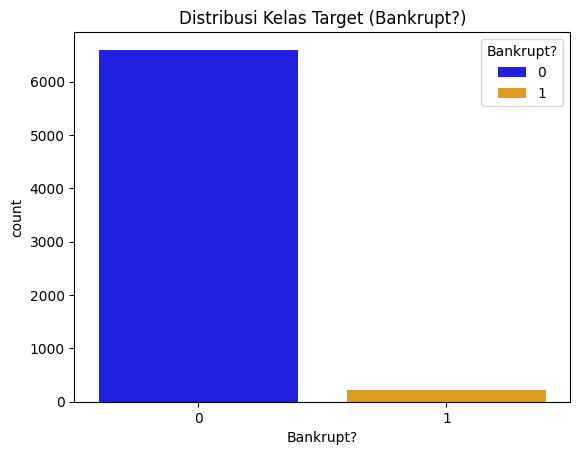

In [5]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

sns.countplot(x='Bankrupt?', hue='Bankrupt?', data=df, palette = ['blue', 'orange'])
plt.title('Distribusi Kelas Target (Bankrupt?)')


In [6]:
x = df.drop('Bankrupt?', axis=1)
y = df['Bankrupt?']

corr = x.corr().abs()
print(corr)


upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
X_reduced = x.drop(columns=to_drop)

print("Fitur yang dihapus karena sangat mirip:", to_drop)
print("Jumlah fitur tersisa:", X_reduced.shape[1])




                                                    ROA(C) before interest and depreciation before interest  \
ROA(C) before interest and depreciation before ...                                           1.000000         
ROA(A) before interest and % after tax                                                       0.940124         
ROA(B) before interest and depreciation after tax                                            0.986849         
Operating Gross Margin                                                                       0.334719         
Realized Sales Gross Margin                                                                  0.332755         
...                                                                                               ...         
Liability to Equity                                                                          0.143629         
Degree of Financial Leverage (DFL)                                                           0.016575         
I

In [7]:
X = df.drop(columns=['Bankrupt?'])

def detect_outliers_iqr(df):
    outlier_summary = {}
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
        outlier_summary[col] = n_outliers
    return pd.Series(outlier_summary).sort_values(ascending=False)

outliers = detect_outliers_iqr(X)
print(outliers.head(20))

Degree of Financial Leverage (DFL)                    1503
Interest Coverage Ratio (Interest expense to EBIT)    1421
Fixed Assets Turnover Frequency                       1418
Current Asset Turnover Rate                           1399
Total Asset Growth Rate                               1381
Interest Expense Ratio                                1362
Cash Flow to Liability                                1212
No-credit Interval                                    1139
Non-industry income and expenditure/revenue           1094
Cash Flow to Sales                                    1052
Continuous Net Profit Growth Rate                     1042
After-tax Net Profit Growth Rate                      1033
Regular Net Profit Growth Rate                        1030
Operating Profit Growth Rate                          1008
Inventory/Working Capital                              944
Contingent liabilities/Net worth                       942
Cash Flow to Total Assets                              8

In [8]:
#nilai < 0
(df < 0).sum().sum()
 

np.int64(0)

In [9]:
#nilai "Nan"
(df == "Nan").sum().sum()  

np.int64(0)

jujur ini fiturnya terlalu banyak untuk membuat pairplot untuk setiap fitur, sehingga saya menggunakan ai untuk membantu menganalisis fitur apa saja yang sebaiknya ditampilkan di pairplot dan boxplot


In [10]:
#memilih fitur fitur penting yang memiliki korelasi tinggi dengan target dan digunakan untuk EDA

target_corr = X_reduced.corrwith(y).abs().sort_values(ascending=False)
print(target_corr.head(15))

selected = target_corr.head(10).index.tolist()
print(selected)

ROA(A) before interest and % after tax                     0.282941
ROA(C) before interest and depreciation before interest    0.260807
Debt ratio %                                               0.250161
Persistent EPS in the Last Four Seasons                    0.219560
Retained Earnings to Total Assets                          0.217779
Current Liability to Assets                                0.194494
Working Capital to Total Assets                            0.193083
Net Income to Stockholder's Equity                         0.180987
Borrowing dependency                                       0.176543
Current Liability to Current Assets                        0.171306
Net Value Per Share (B)                                    0.165399
Current Liabilities/Equity                                 0.153828
Working Capital/Equity                                     0.147221
Operating Profit Per Share (Yuan ¥)                        0.142051
Liability-Assets Flag                           

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


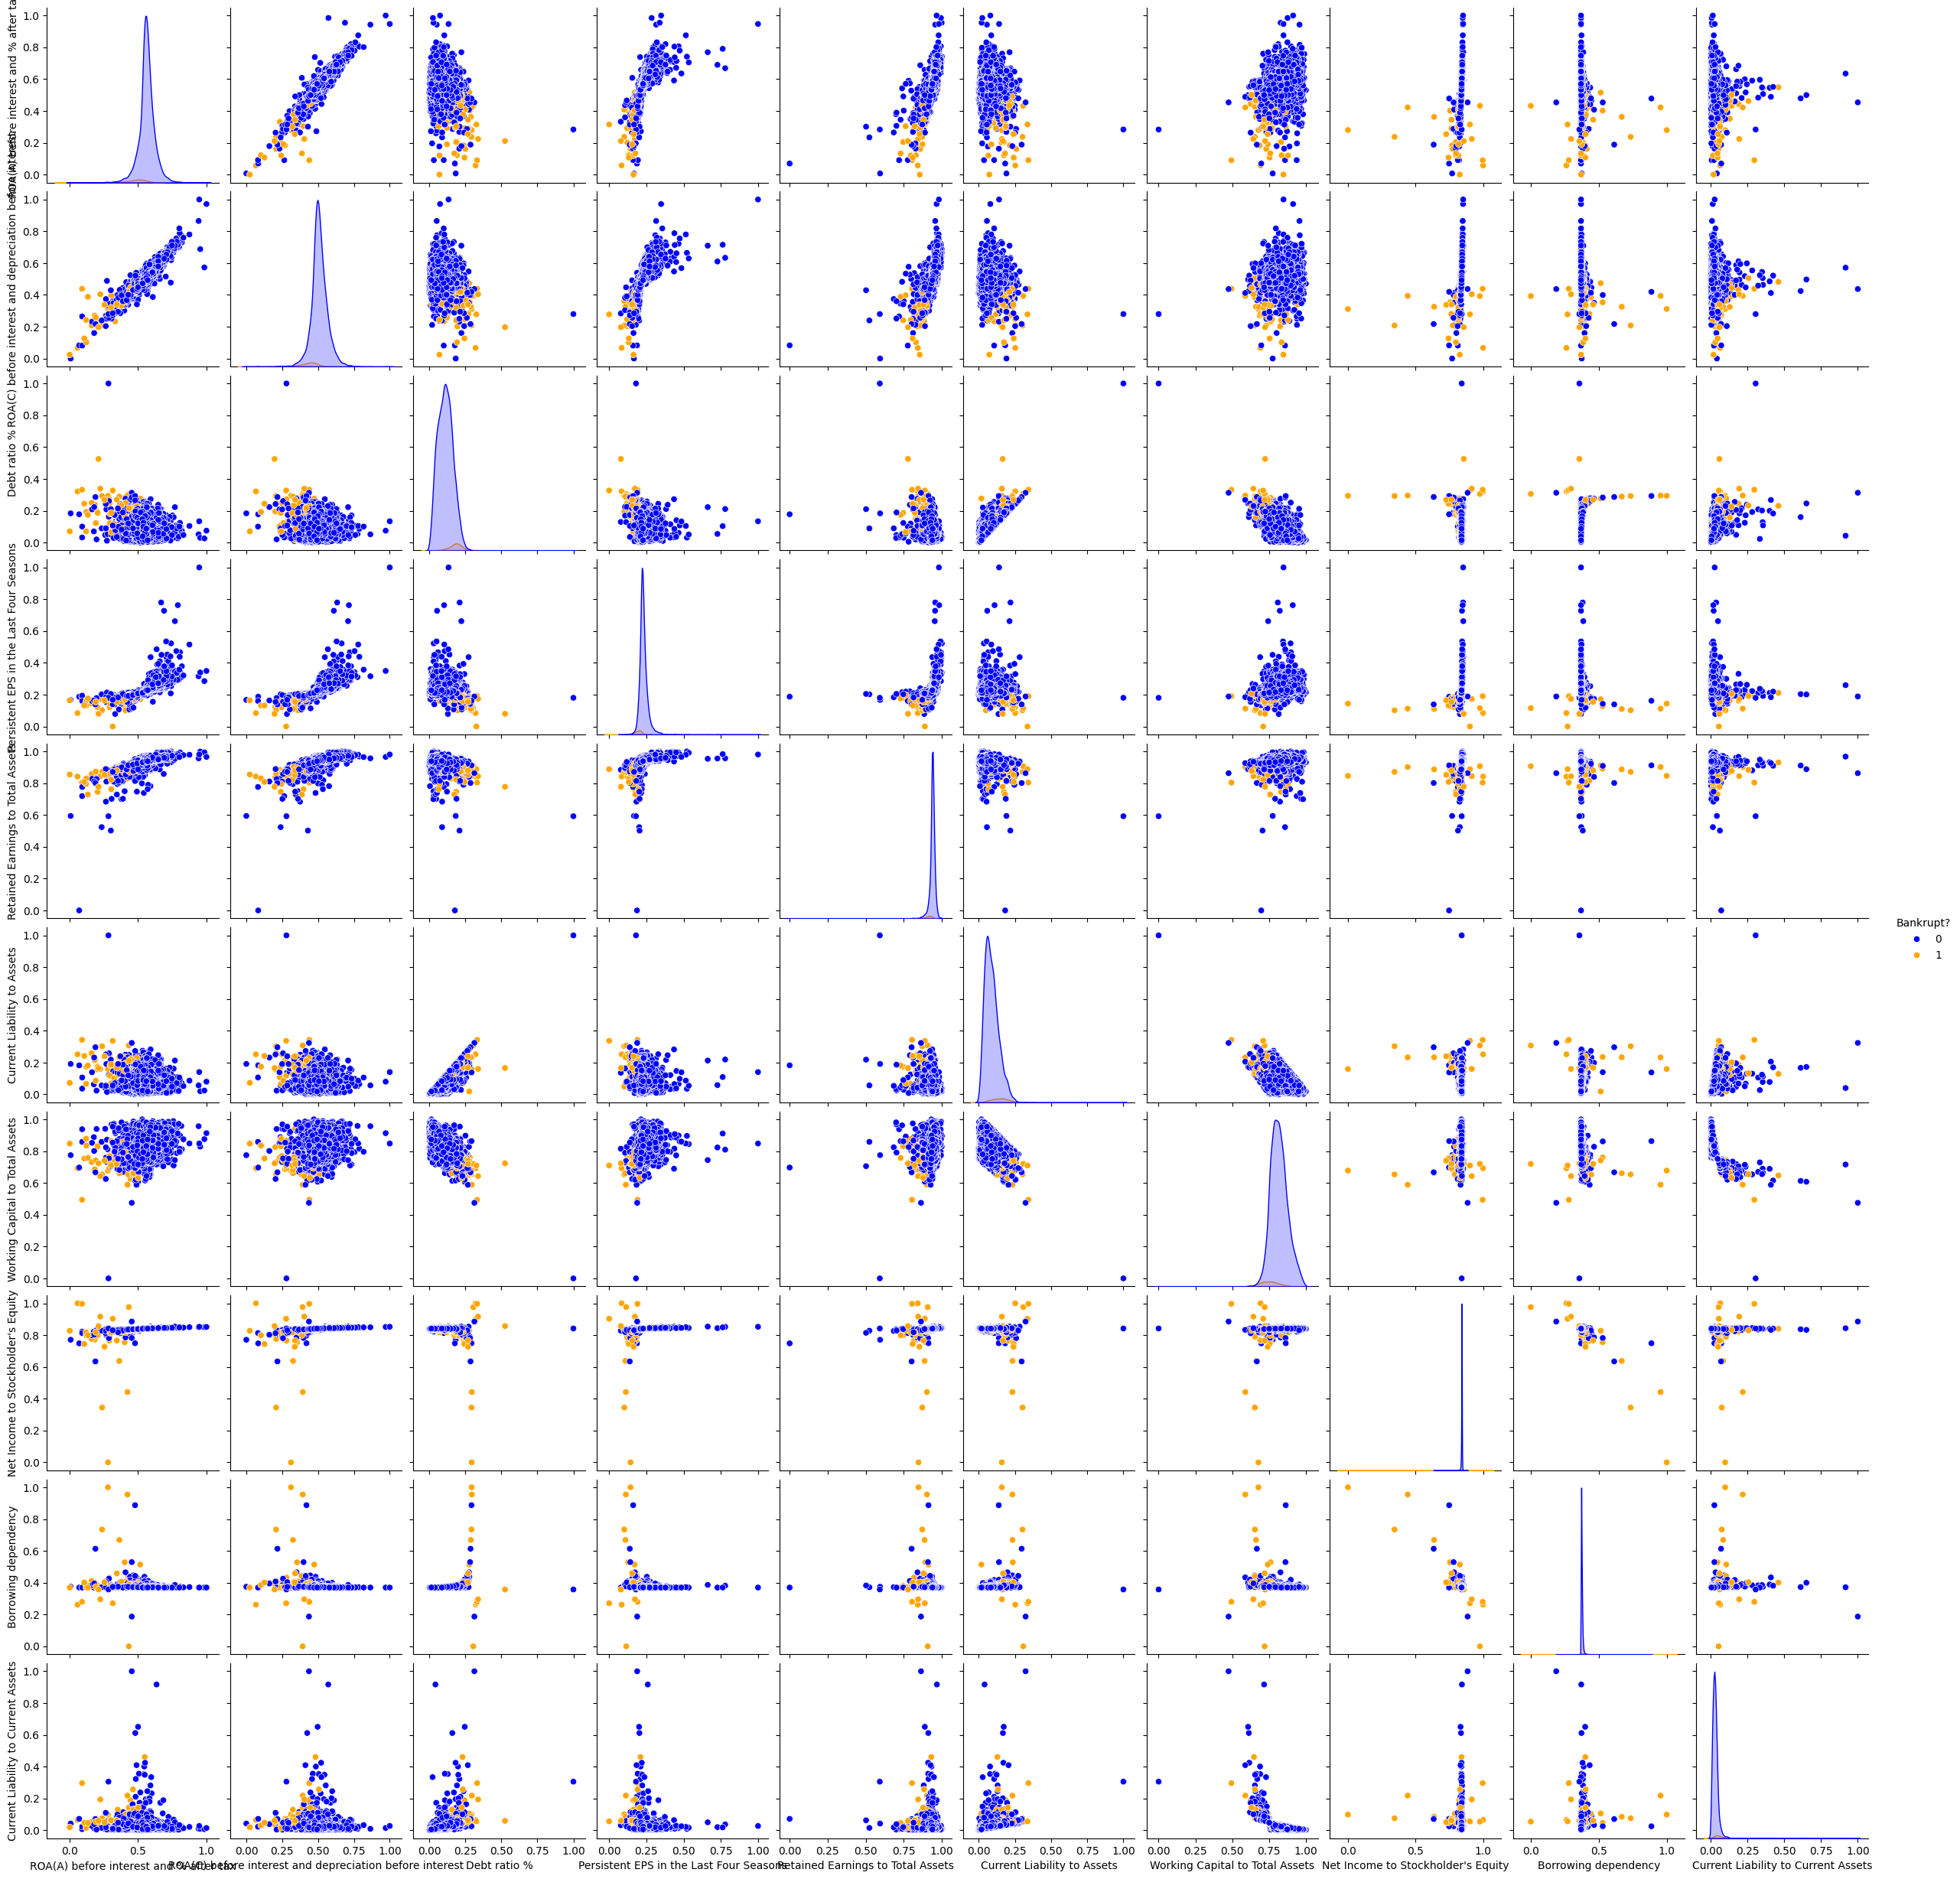

In [11]:
sns.pairplot(df[selected + ['Bankrupt?']], hue='Bankrupt?', palette = ['blue', 'orange'])

intinya di pairplot ini, label 0 dan 1 memiliki pola yang berbeda disini, sehingga bisa digunakan untuk modelling nantinya


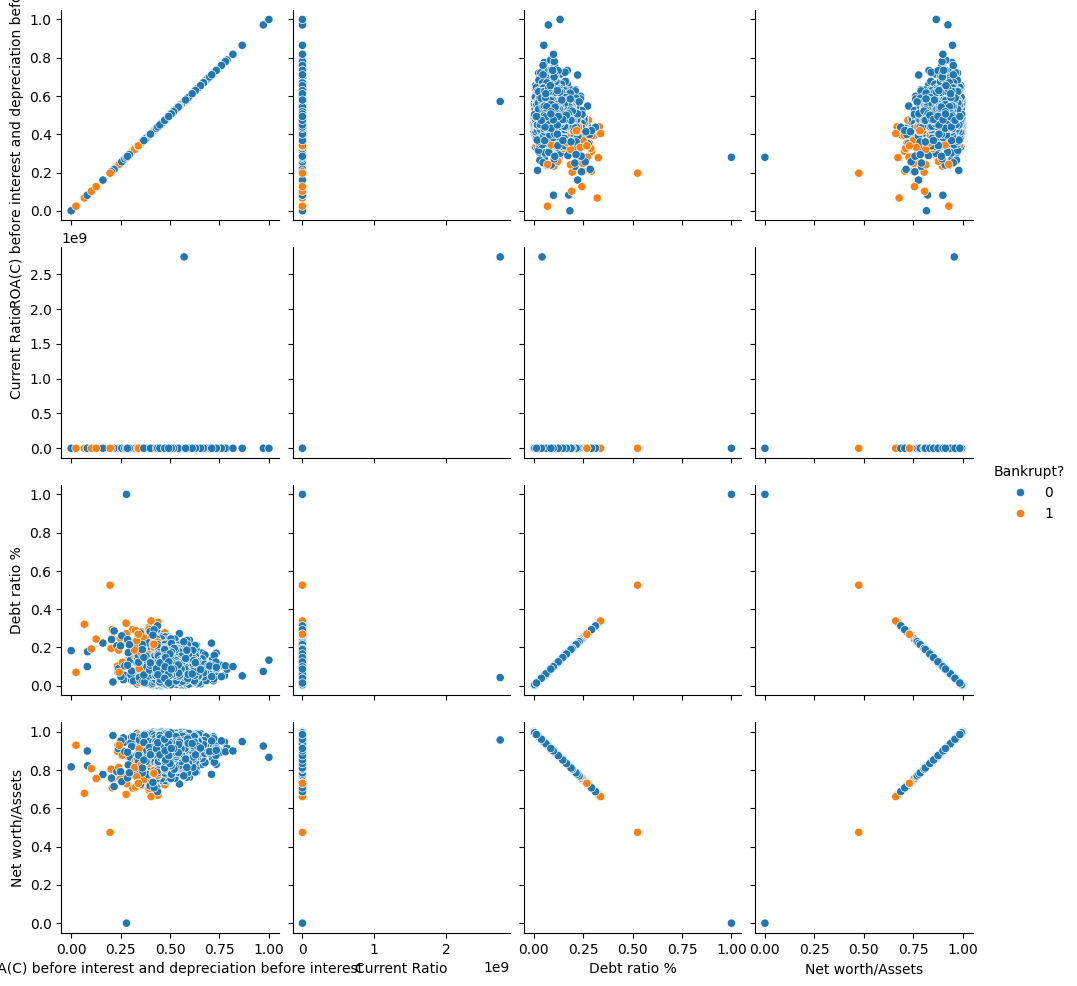

In [12]:
df.columns = df.columns.str.strip()

selected = [
    'ROA(C) before interest and depreciation before interest',
    'Current Ratio',
    'Debt ratio %',
    'Net worth/Assets'
]

sns.pairplot(df[selected + ['Bankrupt?']], hue='Bankrupt?', diag_kind=None)
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [13]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

missing = df.isna().sum()
print(missing[missing > 0])

X = df.drop(columns=['Bankrupt?'])
y = df['Bankrupt?']

if X.isnull().sum().sum() > 0:
    X = X.fillna(X.median(numeric_only=True))



Series([], dtype: int64)


In [14]:
unique_counts = df.nunique()
print(unique_counts[unique_counts == 1])

df.drop(columns=['Net Income Flag'])

Net Income Flag    1
dtype: int64


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,0.035490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6814,0,0.493687,0.539468,0.543230,0.604455,0.604462,0.998992,0.797409,0.809331,0.303510,...,0,0.799927,0.000466,0.623620,0.604455,0.840359,0.279606,0.027064,0.566193,0.029890
6815,0,0.475162,0.538269,0.524172,0.598308,0.598308,0.998992,0.797414,0.809327,0.303520,...,0,0.799748,0.001959,0.623931,0.598306,0.840306,0.278132,0.027009,0.566018,0.038284
6816,0,0.472725,0.533744,0.520638,0.610444,0.610213,0.998984,0.797401,0.809317,0.303512,...,0,0.797778,0.002840,0.624156,0.610441,0.840138,0.275789,0.026791,0.565158,0.097649
6817,0,0.506264,0.559911,0.554045,0.607850,0.607850,0.999074,0.797500,0.809399,0.303498,...,0,0.811808,0.002837,0.623957,0.607846,0.841084,0.277547,0.026822,0.565302,0.044009


In [15]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
# Catatan: Decision Tree secara konsep bisa menangani fitur kategorikal secara langsung tanpa One-Hot Encoding,
# tetapi implementasi DecisionTreeClassifier pada scikit-learn tetap mengharuskan input berupa angka.

In [16]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [17]:
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Distribusi y_train:\n", y_train.value_counts(normalize=True))
print("Distribusi y_test:\n", y_test.value_counts(normalize=True))

Ukuran X_train: (5455, 95)
Ukuran X_test: (1364, 95)
Distribusi y_train:
 Bankrupt?
0    0.967736
1    0.032264
Name: proportion, dtype: float64
Distribusi y_test:
 Bankrupt?
0    0.967742
1    0.032258
Name: proportion, dtype: float64


**Catatan penting:** Decision Tree tidak memerlukan feature scaling (StandardScaler/MinMaxScaler). Split pada Decision Tree dilakukan berdasarkan threshold per fitur satu per satu, bukan berdasarkan jarak antar titik seperti pada KNN atau SVM. Jadi kalian tidak perlu melakukan scaling pada tahap ini.

# 3. Eksperimen Model

## 3.1 Decision Tree dengan Kriteria Gini

Gini Impurity adalah kriteria default pada DecisionTreeClassifier di scikit-learn. Kriteria ini mengukur peluang kesalahan klasifikasi jika sebuah sampel dipilih secara acak dari suatu node.

In [18]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='gini' menggunakan train set.
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix 
)

model_gini = DecisionTreeClassifier(criterion="gini", random_state=42,class_weight='balanced')
model_gini.fit(X_train,y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [19]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

y_pred_gini = model_gini.predict(X_test)


acc_gini = accuracy_score(y_test, y_pred_gini)
prec_gini = precision_score(y_test, y_pred_gini, zero_division=0)
rec_gini = recall_score(y_test, y_pred_gini, zero_division=0)
f1_gini = f1_score(y_test, y_pred_gini, zero_division=0)

print("Accuracy Gini:", acc_gini)
print("Precision Gini:", prec_gini)
print("Recall Gini:", rec_gini)
print("F1-score Gini:", f1_gini)


Accuracy Gini: 0.9596774193548387
Precision Gini: 0.35135135135135137
Recall Gini: 0.29545454545454547
F1-score Gini: 0.32098765432098764


## 3.2 Decision Tree dengan Kriteria Entropy

Entropy (Information Gain) adalah kriteria alternatif yang mengukur tingkat ketidakpastian distribusi kelas pada suatu node.

In [20]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='entropy' menggunakan train set.
# Gunakan nilai hyperparameter lain yang sama seperti model Gini di atas, agar perbandingan adil.

model_entropy = DecisionTreeClassifier(criterion='entropy',random_state=42, class_weight='balanced')
model_entropy.fit(X_train, y_train)


,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [21]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

y_pred_entropy = model_entropy.predict(X_test)

acc_entropy = accuracy_score(y_test, y_pred_entropy)
prec_entropy = precision_score(y_test, y_pred_entropy, zero_division=0)
rec_entropy = recall_score(y_test, y_pred_entropy, zero_division=0)
f1_entropy = f1_score(y_test, y_pred_entropy, zero_division=0)

print('Accuracy Entropy:', acc_entropy)
print('Precision Entropy:', prec_entropy)
print('Recall Entropy:', rec_entropy)
print('F1-score Entropy:', f1_entropy)

Accuracy Entropy: 0.9545454545454546
Precision Entropy: 0.3269230769230769
Recall Entropy: 0.38636363636363635
F1-score Entropy: 0.3541666666666667


## 3.3 Eksperimen Regularisasi: Pengaruh max_depth terhadap Overfitting

Decision Tree yang dibiarkan tumbuh tanpa batas cenderung overfitting terhadap data training. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai max_depth memengaruhi akurasi training dan testing.

In [22]:
# Latih beberapa model DecisionTreeClassifier dengan variasi nilai max_depth,
# misalnya 1, 2, 3, 5, 10, dan None (tanpa batas kedalaman).
# Gunakan kriteria split terbaik dari salah satu percobaan sebelumnya (Gini atau Entropy).

depths = [1,2,3,4,5,10,15,20,30,40,50,70,100,None]
train_acc = []
test_acc = []

for depth in depths:
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth,random_state=42, class_weight='balanced')
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_acc.append(accuracy_score(y_train, y_train_pred))
    test_acc.append(accuracy_score(y_test, y_test_pred))

In [23]:
# Hitung akurasi pada train set dan test set untuk setiap nilai max_depth yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

results = pd.DataFrame({
    'max_depth': depths,
    'train_accuracy': train_acc,
    'test_accuracy': test_acc
})

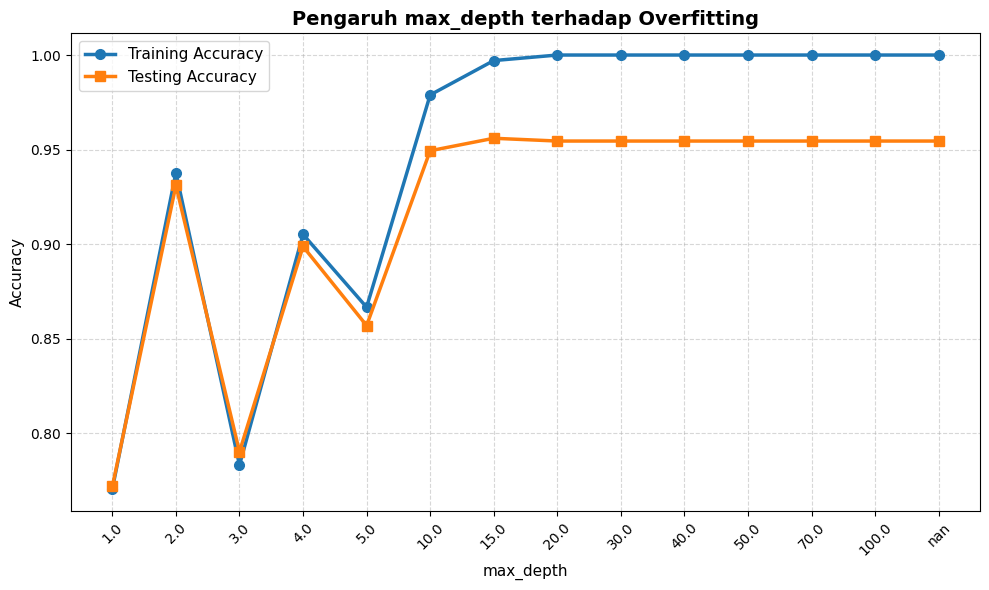

In [24]:
# Plot grafik akurasi training vs testing terhadap max_depth dalam satu chart.
# Amati pada titik berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).

plt.figure(figsize=(10, 6))

x_labels = ["None" if d is None else str(d) for d in results['max_depth']]

plt.plot(x_labels, results['train_accuracy'], marker='o', linewidth=2.5, markersize=7,
         label='Training Accuracy', color='tab:blue')
plt.plot(x_labels, results['test_accuracy'], marker='s', linewidth=2.5, markersize=7,
         label='Testing Accuracy', color='tab:orange')

plt.title('Pengaruh max_depth terhadap Overfitting', fontsize=14, fontweight='bold')
plt.xlabel('max_depth', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# 4. Evaluasi Model

In [25]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model Gini dan Entropy.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Gini", "Entropy"],
    "Accuracy": [acc_gini, acc_entropy],
    "Precision": [prec_gini, prec_entropy],
    "Recall": [rec_gini, rec_entropy],
    "F1-Score": [f1_gini, f1_entropy]
})

print(comparison)

     Model  Accuracy  Precision    Recall  F1-Score
0     Gini  0.959677   0.351351  0.295455  0.320988
1  Entropy  0.954545   0.326923  0.386364  0.354167


In [26]:
cm_gini = confusion_matrix(y_test, y_pred_gini)
cm_entropy = confusion_matrix(y_test, y_pred_entropy)



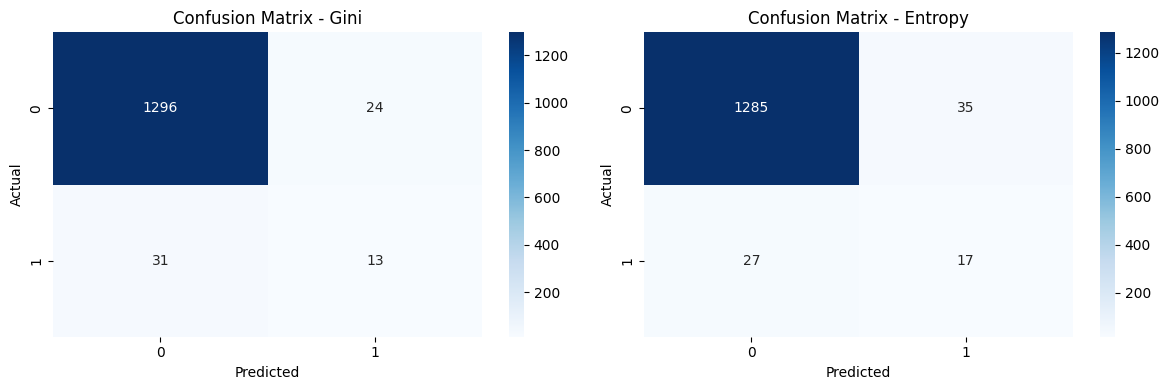

In [27]:
# Tampilkan Confusion Matrix untuk model Gini dan Entropy dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_gini, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Confusion Matrix - Gini")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_entropy, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title("Confusion Matrix - Entropy")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

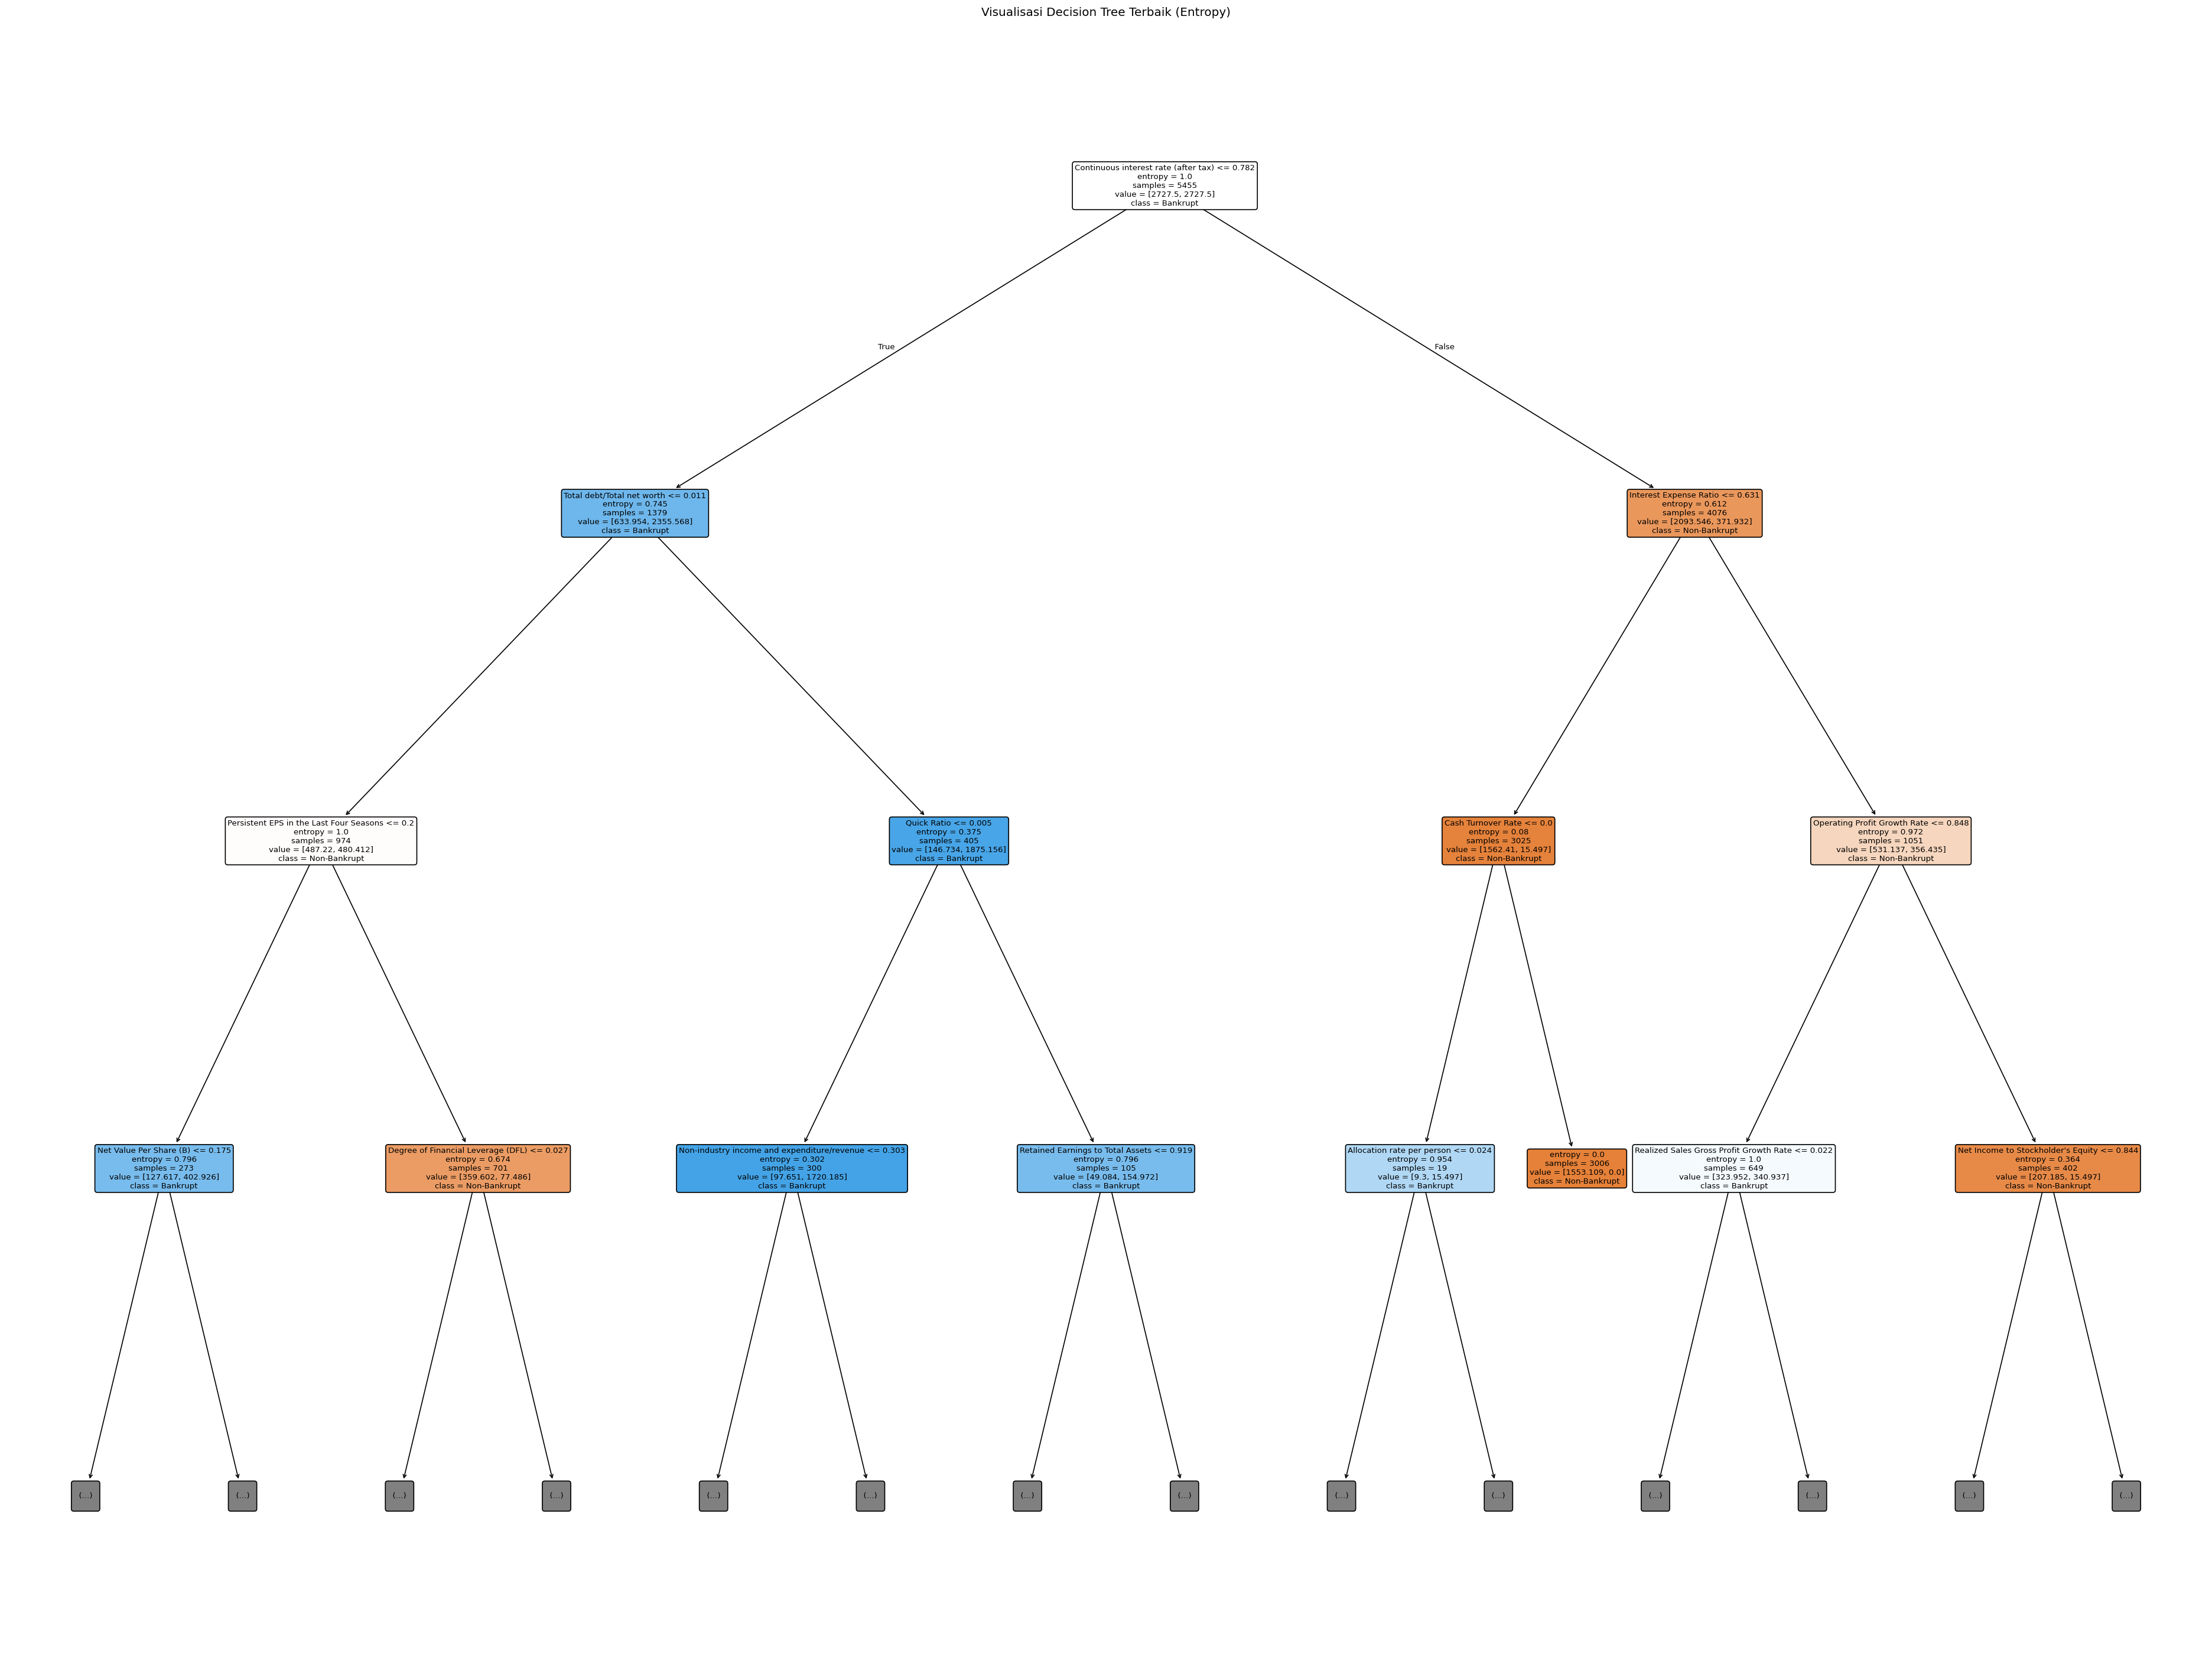

In [28]:
# Visualisasikan struktur Decision Tree (gunakan plot_tree) untuk model dengan performa terbaik.
# Batasi kedalaman visualisasi (misalnya max_depth=2 atau 3 pada parameter plot_tree) agar tetap mudah dibaca.

best_model_name = comparison.sort_values('F1-Score', ascending=False).iloc[0]['Model']
best_model = model_entropy

plt.figure(figsize=(40, 30), dpi=120)
plot_tree(
    best_model,
    feature_names=X.columns,
    class_names=['Non-Bankrupt', 'Bankrupt'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title(f'Visualisasi Decision Tree Terbaik ({best_model_name})')
plt.show()

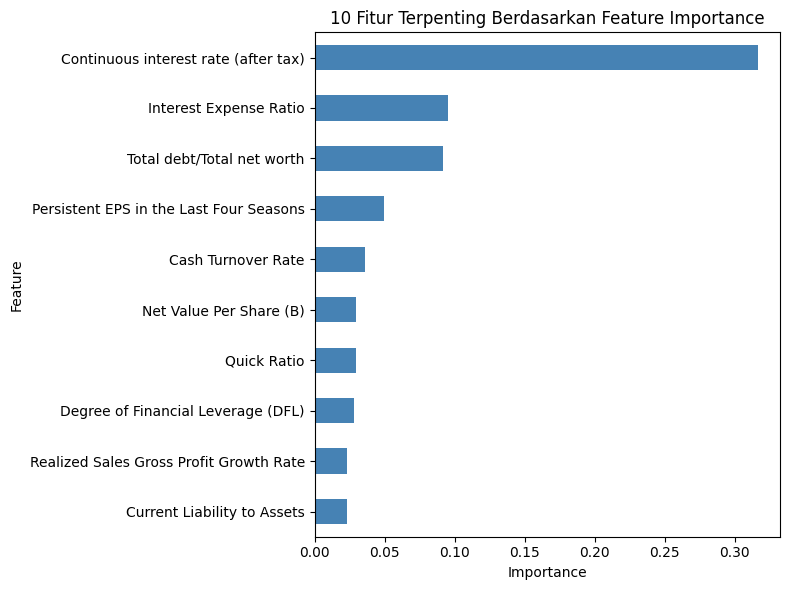

In [29]:
# Tampilkan feature importance dari model terbaik dalam bentuk bar chart horizontal.
# Urutkan dari fitur yang paling berpengaruh.

feature_importance = pd.Series(best_model.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 6))
feature_importance.sort_values().plot(kind='barh', color='steelblue')
plt.title('10 Fitur Terpenting Berdasarkan Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa Decision Tree dengan kriteria Gini vs Entropy. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (max_depth). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Fitur apa yang paling berpengaruh terhadap prediksi model, berdasarkan feature importance?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

Jawab :

1. hasil dari kriteria gini dan entropy tidak terlalu signifikan, untuk akurasi berada pada 96 persen, sedangkan sisanya itu berada diantara 30-40 persen (sebelumnya lebih kecil lagi, namun setelah di tambahkan parameter 'class_weight=balanced', hasiilnya jadi lebih optimal). namun, walau tidak terlalu signifikan, disini Gini lebih baik untuk menebak false positif, namun untuk false negatif (aslinya bangkrut tapi di anggap tidak bangkrut), entropy mendapatkan hasil yang lebih optimal. untuk dataset ini kita bisa menyimpulkan metode entropy lebih baik dari gini, karena entnopy menebak false negative lebih banyak, yang artinya dia bisa untuk mencegah kebangkrutan dengan mendeteksi kebangkrutan lebih baik daripada gini

    namun sebelum masuk ke pembahasannya, kita perlu tau dulu bahwa target pada dataset kali ini sangat imbalance, yang dimana label 0 ada 96,8% sedangkan label 1 hanya sekitar 3% saja, ini membuat akurasi desicion tree bisa sangat besar karena mayoritas data hanya berada pada label 0, sehingga model cenderung untuk memprediksi 0, sebagai perbandingan aja, jika model menebak secara acak label 0, model tersebut memiliki kemungkinan benar sebesar 96,8%. hal ini dibuktikan oleh metode evaluasi yang lain yang dibawah 40 persen, sehingga sulit untuk memprediksi apakah perusahaan bangkrut atau tidak 

    kenapa hasilnya bisa berbeda? dari yang saya baca, kita bisa lihat dari bagaimana gini dan entropy memisah suatu node. Entropy mengukur tingkat ketidakpastian. Karena penalti logaritmiknya yang berat terhadap node yang masih memiliki ketidakpastian, Entropy memaksa algoritma untuk mencari titik potong (split threshold) yang benar-benar bisa memurnikan sampel kelas minoritas, meskipun itu membutuhkan pembelahan yang lebih spesifik. sedangkan, Gini Index bekerja dengan meminimalkan misclassification error secara agregat. Akibatnya, Gini cenderung mengambil strategi aman, dengan mengisolasi kelompok mayoritas ke dalam satu cabang besar dan membiarkan cabang sisanya tetap tercampur 

2. berdasarkan eksperimen regularisasi, disini saya menggunakan kedalaman [1, 2, 3, 4, 5, 10, 15, 20, 30, 40, 50, 70, 100, dan None], pada kedalaman 1 sampai 3, hasil test masih cenderung untuk mengikuti hasil dari train, namun pada kedalaman 4, hasil test mulai lebih menurun daripada hasil test, walau secara akurasi mereka meningkat. dari 4 - 10, akurasi keduanya sangat meningkat drastis, walau test tetap dibawah train. pada 10-15, akurasi dari train mulai menunjukan akurasi yang tidak terlalu naik, sedangkan pada test akurasinya sudah cukup jauh dari train, dan pada puncaknya di kedalaman 20, akurasi dari test mulai turun dan setelah itu train dan test mulai konstan pada akurasi tersebut. hal tersebut menunjukkan bahwa model terlalu kompleks sehingga benar benar mengingat data dan menjadi overfitting.

3. yang paling penting di data ini adalah fitur 'continuous interest rate(after task), dengan nilai sekitar 0,30, lalu di susul oleh interest expense tatio dan total debt. ini menunjukan bahwa indikator yang berkaitan dengan beban bunga dan hutang memiiki kontribusi yang besar terhadap proses pengambilan keputusan oleh model decision tree ini.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba pruning dengan ccp_alpha, membandingkan dengan model lain, atau mencoba variasi hyperparameter lain seperti min_samples_leaf), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

kesimpulan praktikum kali ini, hasil perbandingkannya menunjukan bahwa entropy memberikan hasil yang lebih baik karena memprediksi kebankrutan suatu perusahaan, namun, hasil ini tidak memuaskan karena walau akurasinya sangat tinggi, f1 score (terutama recall)nya memberikan hasil yang rendah. seperti yang saya sebutkan diatas tadi, hal ini dikarenakan dataset yang sangat inbalance, sehingga model pun memberikan hasil yang cenderung mengarah pada label yang lebih banyak. namun, dengan analisis ini kita bisa menangkap bahwa metode Entropy itu cocok digunakan untuk suatu fitur yang tidak seimbang. 

saran untuk kedepannya, tolong dataset nya jangan yang fiturnya sangat banyak :), saya bingung ketika ingin melihat distribusi setiap fitur karena memakan waktu yang sangat lama untuk di render, tapi ini mungkin dikarenakan keterbatasan ilmu yang saya miliki, oleh karena itu saya harap di pertemuan selanjutnya dibahas mengenai bagaimana cara menganalisis suatu dataset yang memiliki banyak sekali fitur.

lalu, mungkin juga untuk dataset yang tidak seimbang, saya penasaran jika mencoba dengan menggunakan metode sampling karena dari hasil analisis ini, walau menggunakan decision tree yang tahan terhadap inbalance, saya merasa hasil yang saya dapatkan ini juga dipengaruhi oleh ketidakseimbangan data tersebut (atau mungkin saya sendiri yang tidak memiliki ilmunya). terakhir mungkin juga bisa melakukan metode metode yang disebutkan diatas (misalnya mencoba pruning dengan ccp_alpha, membandingkan dengan model lain, atau mencoba variasi hyperparameter lain seperti min_samples_leaf), namun tolong jelaskan terlebih dahulu ini metode apa